In [ ]:
# Cell 1 - run information (required)
import os, subprocess, sys, random, numpy as np, torch
from importlib import metadata as _md
try:                                    # Colab: the repo clone may live in Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
# Commit of the GitHub repo these notebooks belong to. Without a git clone, copy the short hash shown
# on the GitHub repo page (e.g. "a1b2c3d") and paste it here.
COMMIT_HASH = ""
# If a git clone of the repo exists (folder with .git), the commit is read from it instead.
_candidates = [os.environ.get("REPO_DIR", ""), "/content/drive/MyDrive/data266-lab2-team42",
               "/content/data266-lab2-team42", os.getcwd()]
REPO_DIR = next((d for d in _candidates if d and os.path.isdir(os.path.join(d, ".git"))), None)
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if REPO_DIR:
    os.chdir(REPO_DIR)
    commit = subprocess.run(["git", "-c", "safe.directory=*", "rev-parse", "--short", "HEAD"],
                            capture_output=True, text=True).stdout.strip()
elif COMMIT_HASH:
    commit = COMMIT_HASH + " (from GitHub page)"
else:
    commit = "MISSING"
    print("WARNING: paste the commit hash from your GitHub repo page into COMMIT_HASH and re-run this cell.")
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

def _version(pkg):
    try:
        return _md.version(pkg)
    except _md.PackageNotFoundError:
        return "not installed"
print({p: _version(p) for p in ["diffusers", "transformers", "peft", "accelerate", "open_clip_torch",
                                "lpips", "torchmetrics", "torch-fidelity", "huggingface_hub"]})

# Part 2 (1/2): data preparation, LoRA training and image generation

This notebook holds the **executed** data-preparation, training and generation runs on a Colab T4
(outputs saved from the original runs on 23–27 Oct 2026). Evaluation, safety, memorization, the human
evaluation and the Hugging Face model card/dataset release are in **`p2_evaluate.ipynb`**.

* Cell 1 above prints the run information required by C1.4. It was added after training and is re-run
  from the tagged repository clone, so its commit hash is the tagged commit.
* The two set-up cells that were originally executed at the end of the session (re-clone Diffusers,
  install `bitsandbytes`) are placed directly after the install cell, where they belong.
* The 20 evaluation prompts are frozen in the prompt cell **before** the training cells
  (training logs start 24 Oct 2026, 00:00); the same file is committed as `eval/p2_fixed_20_prompts.json`.
* Peak GPU memory was measured with an `nvidia-smi` poller during two repeat runs with identical
  settings (cell after the training table); training times come from the original runs.

# DATA 266 Lab 2 - Part 2
## Stable Diffusion LoRA fine-tuning on a T4

This executable Colab notebook prepares the Naruto BLIP captioned dataset, creates the required seed-266 90/10 split, freezes 20 evaluation prompts, trains LoRA rank 4 and rank 16 with the same budget, generates base/run1/run2 images, computes KID/CLIP/LPIPS, creates human-evaluation and memorization files, and provides optional Hugging Face upload cells.

Drive project path: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2


In [ ]:
# 1. Mount Drive and configure the experiment
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, sys, json, random, hashlib, subprocess, time, warnings
warnings.filterwarnings('ignore')
import numpy as np

PROJECT_DIR = Path('/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2')
DATA_DIR = PROJECT_DIR/'data'
PREPARED_DIR = DATA_DIR/'prepared'
TRAIN_DIR, TEST_DIR = PREPARED_DIR/'train', PREPARED_DIR/'test'
PROMPT_DIR, MODEL_DIR = PROJECT_DIR/'prompts', PROJECT_DIR/'models'
OUTPUT_DIR, GENERATED_DIR = PROJECT_DIR/'outputs', PROJECT_DIR/'outputs'/'generated'
RESULTS_DIR = PROJECT_DIR/'results'
for p in [PROJECT_DIR,DATA_DIR,PREPARED_DIR,TRAIN_DIR,TEST_DIR,PROMPT_DIR,MODEL_DIR,OUTPUT_DIR,GENERATED_DIR,RESULTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

SEED = 266
random.seed(SEED); np.random.seed(SEED)
MODEL_NAME = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
DATASET_NAME = 'lambdalabs/naruto-blip-captions'
RESOLUTION = 512
MAX_TRAIN_STEPS = 1500
TRAIN_BATCH_SIZE = 1
GRADIENT_ACCUMULATION = 4
LEARNING_RATE = 1e-4
RUN_TRAINING = True
UPLOAD_TO_HUB = True

def git_commit(path):
    try:
        r = subprocess.run(['git','rev-parse','--short','HEAD'], cwd=path, capture_output=True, text=True)
        return r.stdout.strip() or 'not-available'
    except Exception:
        return 'not-available'
print({'commit':git_commit(PROJECT_DIR),'python':sys.version.split()[0],'seed':SEED,
       'model':MODEL_NAME,'dataset':DATASET_NAME,'project_dir':str(PROJECT_DIR)})


Mounted at /content/drive
{'commit': 'not-available', 'python': '3.13.16', 'seed': 266, 'model': 'stable-diffusion-v1-5/stable-diffusion-v1-5', 'dataset': 'lambdalabs/naruto-blip-captions', 'project_dir': '/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2'}


In [ ]:
# 2. Install dependencies and verify the T4
!pip -q install transformers accelerate datasets peft safetensors bitsandbytes torchmetrics lpips open_clip_torch pillow pandas matplotlib seaborn scikit-image huggingface_hub
!rm -rf /content/diffusers
!git clone -q --depth 1 https://github.com/huggingface/diffusers.git /content/diffusers
!pip -q install -e /content/diffusers
!pip -q install -r /content/diffusers/examples/text_to_image/requirements.txt

import torch
import pandas as pd
import matplotlib.pyplot as plt
print({'torch':torch.__version__,'cuda':torch.cuda.is_available(),
       'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
       'cuda_version':torch.version.cuda})
assert torch.cuda.is_available(), 'Select Runtime > Change runtime type > T4 GPU.'

!pip uninstall -y torchao


  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for diffusers (pyproject.toml) ... done
{'torch': '2.11.0+cu130', 'cuda': True, 'gpu': 'Tesla T4', 'cuda_version': '13.0'}


In [35]:
# 3. Hugging Face login
from getpass import getpass
from huggingface_hub import login
HF_TOKEN = os.environ.get('HF_TOKEN','')
if not HF_TOKEN:
    HF_TOKEN = getpass('HF token, or press Enter if already authenticated: ')
if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)


HF token, or press Enter if already authenticated: ··········


In [39]:
# Fix PEFT/TorchAO compatibility issue

import sys
import subprocess
import importlib.util
import importlib.metadata as metadata

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "uninstall",
        "-y",
        "torchao"
    ],
    check=False
)

print(
    "torchao importable:",
    importlib.util.find_spec("torchao") is not None
)

try:
    print("torchao version:", metadata.version("torchao"))
except metadata.PackageNotFoundError:
    print("torchao is successfully removed.")

torchao importable: False
torchao is successfully removed.


In [37]:
import shutil
import subprocess
import sys
from pathlib import Path

REPO_DIR = Path("/content/diffusers")
TRAIN_SCRIPT = REPO_DIR / "examples/text_to_image/train_text_to_image_lora.py"

# Reclone only if the required script is missing
if not TRAIN_SCRIPT.exists():
    if REPO_DIR.exists():
        shutil.rmtree(REPO_DIR)

    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            "https://github.com/huggingface/diffusers.git",
            str(REPO_DIR)
        ],
        check=True
    )

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "-e",
            str(REPO_DIR)
        ],
        check=True
    )

requirements_file = REPO_DIR / "examples/text_to_image/requirements.txt"

if requirements_file.exists():
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "-r",
            str(requirements_file)
        ],
        check=True
    )

print("Repository exists:", REPO_DIR.exists())
print("Script exists:", TRAIN_SCRIPT.exists())
print("Training script:", TRAIN_SCRIPT)

assert TRAIN_SCRIPT.exists(), "Training script is still missing."

Repository exists: True
Script exists: True
Training script: /content/diffusers/examples/text_to_image/train_text_to_image_lora.py


In [41]:
# Install and verify bitsandbytes for 8-bit Adam

import sys
import subprocess

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--upgrade",
        "bitsandbytes"
    ],
    check=True
)

import bitsandbytes as bnb

print("bitsandbytes version:", bnb.__version__)
print("bitsandbytes imported successfully.")

bitsandbytes version: 0.50.2
bitsandbytes imported successfully.


## 2.1 Data preparation
The dataset is checked for corrupted and exact duplicate images, resized to 512 by 512, and split into 90 percent training and 10 percent test with seed 266.


In [ ]:
# 4. Download and clean the captioned dataset
from datasets import load_dataset
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
raw_dataset = load_dataset(DATASET_NAME, split='train')
print(raw_dataset)

def find_col(cols, names):
    for n in names:
        if n in cols: return n
    raise ValueError(f'No column found in {cols}')
IMAGE_COLUMN = find_col(raw_dataset.column_names, ['image','img'])
CAPTION_COLUMN = find_col(raw_dataset.column_names, ['text','caption','prompt','description'])
print({'image_column':IMAGE_COLUMN,'caption_column':CAPTION_COLUMN})

def digest(im):
    return hashlib.sha256(im.convert('RGB').tobytes()).hexdigest()

records, seen = [], set()
removed_corrupt = removed_duplicate = 0
for i in range(len(raw_dataset)):
    try:
        im = raw_dataset[i][IMAGE_COLUMN].convert('RGB'); im.load()
        h = digest(im)
        if h in seen:
            removed_duplicate += 1; continue
        seen.add(h)
        cap = str(raw_dataset[i][CAPTION_COLUMN]).strip() or 'a Naruto-style anime character'
        records.append({'image':im,'caption':cap,'source_index':i,'sha256':h})
    except Exception:
        removed_corrupt += 1
assert len(records) >= 500, f'Found only {len(records)} usable images.'

from sklearn.model_selection import train_test_split
idx = np.arange(len(records))
train_idx, test_idx = train_test_split(idx, test_size=.10, random_state=SEED, shuffle=True)
train_idx, test_idx = sorted(train_idx.tolist()), sorted(test_idx.tolist())

def write_split(indices, folder):
    for p in folder.glob('*'):
        if p.is_file(): p.unlink()
    rows = []
    for j, i in enumerate(indices):
        r = records[i]; fn = f'{j:05d}.png'
        r['image'].resize((RESOLUTION,RESOLUTION), Image.Resampling.LANCZOS).save(folder/fn)
        rows.append({'file_name':fn,'text':r['caption'],'source_index':int(r['source_index']),'sha256':r['sha256']})
    with open(folder/'metadata.jsonl','w') as f:
        for row in rows: f.write(json.dumps(row)+'\n')
    return rows

train_metadata = write_split(train_idx, TRAIN_DIR)
test_metadata = write_split(test_idx, TEST_DIR)
cleaning_report = {'dataset':DATASET_NAME,'original_count':len(raw_dataset),
 'usable_unique_count':len(records),'removed_corrupt':removed_corrupt,'removed_duplicate':removed_duplicate,
 'train_count':len(train_metadata),'test_count':len(test_metadata),'split_seed':SEED,'resolution':[512,512]}
with open(RESULTS_DIR/'data_cleaning_report.json','w') as f: json.dump(cleaning_report,f,indent=2)
print(json.dumps(cleaning_report,indent=2))


Repo card metadata block was not found. Setting CardData to empty.


Dataset({
    features: ['image', 'text'],
    num_rows: 1221
})
{'image_column': 'image', 'caption_column': 'text'}
{
  "dataset": "lambdalabs/naruto-blip-captions",
  "original_count": 1221,
  "usable_unique_count": 1221,
  "removed_corrupt": 0,
  "removed_duplicate": 0,
  "train_count": 1098,
  "test_count": 123,
  "split_seed": 266,
  "resolution": [
    512,
    512
  ]
}


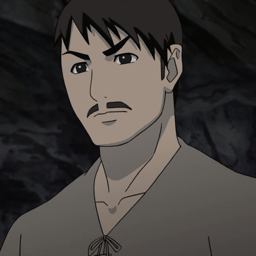

a man with dark hair and brown eyes


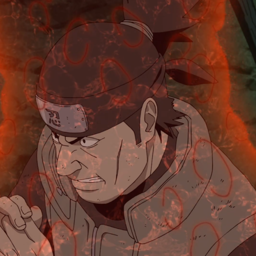

a man in a hoodie with a fire in the background


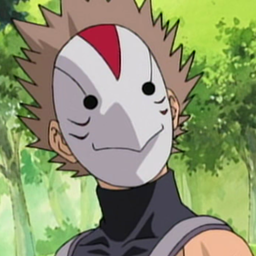

a man with a red hair and a black shirt


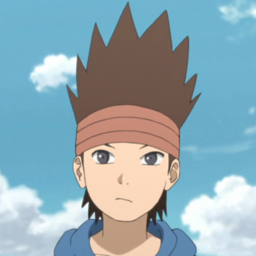

a man in a blue shirt and headband


In [ ]:
# 5. Display examples and save dataset limitations
import matplotlib.pyplot as plt
from IPython.display import display
for row in train_metadata[:4]:
    display(Image.open(TRAIN_DIR/row['file_name']).resize((256,256)))
    print(row['text'])
dataset_description = {
 'dataset':DATASET_NAME,
 'limitations':[
  'The dataset is concentrated in one copyrighted anime domain and is not representative of general image distributions.',
  'BLIP captions are automatically generated and may omit objects, relationships, or style details.'
 ],
 'license_note':'Use only within the dataset/model licenses and non-commercial academic research context.',
 'cleaning_report':cleaning_report
}
with open(RESULTS_DIR/'dataset_description.json','w') as f: json.dump(dataset_description,f,indent=2)


## Fixed 20-prompt evaluation set
This is written before training. It contains 10 held-out in-domain captions, 5 out-of-domain prompts, and 5 compositional prompts. Existing files are loaded unchanged.


In [ ]:
# 6. Create and freeze the 20 prompts
PROMPT_FILE = PROMPT_DIR/'fixed_20_prompts.json'
if PROMPT_FILE.exists():
    with open(PROMPT_FILE) as f: prompt_rows = json.load(f)
else:
    rng = random.Random(SEED)
    prompt_rows = [{'category':'in_domain','prompt':x['text']} for x in rng.sample(test_metadata,10)]
    prompt_rows += [{'category':'out_of_domain','prompt':x} for x in [
      'a watercolor painting of a mountain village at sunrise',
      'a realistic photograph of a red fox in a snowy forest',
      'a futuristic glass skyscraper floating above the ocean',
      'a bowl of fresh tropical fruit on a wooden table',
      'an impressionist painting of a quiet European train station']]
    prompt_rows += [{'category':'compositional','prompt':x} for x in [
      'two anime characters, one wearing red and one wearing blue, standing side by side',
      'a young ninja character holding a glowing green sword beside a small orange fox',
      'three characters in a forest, one sitting, one standing, and one jumping',
      'an anime character riding a large bird above a village with mountains in the background',
      'two characters exchanging a scroll in front of a red wooden gate at sunset']]
    for i, row in enumerate(prompt_rows): row['prompt_id'] = f'P{i+1:02d}'
    with open(PROMPT_FILE,'w') as f: json.dump(prompt_rows,f,indent=2)
print(pd.DataFrame(prompt_rows).to_string(index=False))


     category                                                                                  prompt prompt_id
    in_domain                                    a woman with purple hair and a scarf around her neck       P01
    in_domain                                           two people standing next to each other people       P02
    in_domain                                                    a woman with red hair and a necklace       P03
    in_domain                                                          a man with pink hair and a hat       P04
    in_domain                                        two people with one person looking at the camera       P05
    in_domain                                  two people hugging each other people in the background       P06
    in_domain                                                          a man in a blue jacket and tie       P07
    in_domain                                                           a cat sitting on top of a bed   

## 2.2 Fine-tuning
Both runs use identical data and a 1,500-step budget. Only the LoRA rank changes: rank 4 versus rank 16.


In [ ]:
# 7. Train LoRA rank 4

RUN1_DIR = MODEL_DIR / "lora_rank4"
RUN1_DIR.mkdir(exist_ok=True)

t0 = time.time()

if RUN_TRAINING and not (
    RUN1_DIR / "pytorch_lora_weights.safetensors"
).exists():

    !accelerate launch --mixed_precision=fp16 \
      /content/diffusers/examples/text_to_image/train_text_to_image_lora.py \
      --mixed_precision=fp16 \
      --pretrained_model_name_or_path={MODEL_NAME} \
      --train_data_dir={TRAIN_DIR} \
      --image_column=image \
      --caption_column=text \
      --resolution={RESOLUTION} \
      --center_crop \
      --random_flip \
      --train_batch_size={TRAIN_BATCH_SIZE} \
      --gradient_accumulation_steps={GRADIENT_ACCUMULATION} \
      --gradient_checkpointing \
      --use_8bit_adam \
      --learning_rate={LEARNING_RATE} \
      --lr_scheduler=constant \
      --lr_warmup_steps=0 \
      --max_train_steps={MAX_TRAIN_STEPS} \
      --checkpointing_steps=500 \
      --output_dir={RUN1_DIR} \
      --rank=4 \
      --seed={SEED}

else:
    print("Run 1 exists or training is disabled.")

run1_seconds = time.time() - t0

assert (
    RUN1_DIR / "pytorch_lora_weights.safetensors"
).exists(), "Run 1 failed. Check the traceback above."

print({
    "run": "lora_rank4",
    "training_seconds": run1_seconds
})

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_processes` was set to a value of `1`
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
10/23/2026 23:12:44 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
10/23/2026 23:12:44 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
10/23/2026 

In [ ]:
# 8. Train LoRA rank 16
RUN2_DIR = MODEL_DIR / "lora_rank16"
RUN2_DIR.mkdir(exist_ok=True)

t0 = time.time()

if RUN_TRAINING and not (
    RUN2_DIR / "pytorch_lora_weights.safetensors"
).exists():

    !accelerate launch --mixed_precision=fp16 \
      /content/diffusers/examples/text_to_image/train_text_to_image_lora.py \
      --mixed_precision=fp16 \
      --pretrained_model_name_or_path={MODEL_NAME} \
      --train_data_dir={TRAIN_DIR} \
      --image_column=image \
      --caption_column=text \
      --resolution={RESOLUTION} \
      --center_crop \
      --random_flip \
      --train_batch_size={TRAIN_BATCH_SIZE} \
      --gradient_accumulation_steps={GRADIENT_ACCUMULATION} \
      --gradient_checkpointing \
      --use_8bit_adam \
      --learning_rate={LEARNING_RATE} \
      --lr_scheduler=constant \
      --lr_warmup_steps=0 \
      --max_train_steps={MAX_TRAIN_STEPS} \
      --checkpointing_steps=500 \
      --output_dir={RUN2_DIR} \
      --rank=16 \
      --seed={SEED}

else:
    print("Run 2 exists or training is disabled.")

run2_seconds = time.time() - t0

assert (
    RUN2_DIR / "pytorch_lora_weights.safetensors"
).exists(), "Run 2 failed. Check the traceback above."

print({
    "run": "lora_rank16",
    "training_seconds": run2_seconds
})

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_processes` was set to a value of `1`
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
10/24/2026 00:01:26 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda

Mixed precision type: fp16

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
10/24/2026 00:01:26 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/main/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
10/24/2026 

In [ ]:
# 9. Required training comparison table
from safetensors.torch import load_file
def parameter_count(folder):
    p = folder/'pytorch_lora_weights.safetensors'
    return int(sum(x.numel() for x in load_file(str(p),device='cpu').values())) if p.exists() else None
training_summary = pd.DataFrame([
 {'run':'lora_rank4','rank':4,'trainable_parameters':parameter_count(RUN1_DIR),'learning_rate':LEARNING_RATE,
  'steps':MAX_TRAIN_STEPS,'batch_size':TRAIN_BATCH_SIZE,'training_seconds':run1_seconds,'gpu_hours':run1_seconds/3600},
 {'run':'lora_rank16','rank':16,'trainable_parameters':parameter_count(RUN2_DIR),'learning_rate':LEARNING_RATE,
  'steps':MAX_TRAIN_STEPS,'batch_size':TRAIN_BATCH_SIZE,'training_seconds':run2_seconds,'gpu_hours':run2_seconds/3600}
])
training_summary.to_csv(RESULTS_DIR/'training_summary.csv',index=False)
display(training_summary)


,run,rank,trainable_parameters,learning_rate,steps,batch_size,training_seconds,gpu_hours
0,lora_rank4,4,797184,0.0001,1500,1,2921.444178,0.811512
1,lora_rank16,16,3188736,0.0001,1500,1,2907.956229,0.807766


In [42]:
# Measure peak GPU memory safely without overwriting the original models

import gc
import os
import sys
import time
import subprocess
import pandas as pd
from pathlib import Path

# Release common evaluation models from GPU memory
for name in [
    "pipe", "base_pipe", "lora_pipe", "rank4_pipe", "rank16_pipe",
    "clip_model", "clip_preprocess", "lpips_model", "metric"
]:
    globals().pop(name, None)

gc.collect()

try:
    import torch
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        print("GPU memory allocated after cleanup:",
              torch.cuda.memory_allocated() / 1024**3, "GiB")
except Exception as exc:
    print("GPU cleanup warning:", exc)


PROJECT_DIR = Path("/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
TRAIN_DIR = PROJECT_DIR / "data/prepared/train"

MODEL_NAME = "stable-diffusion-v1-5/stable-diffusion-v1-5"
TRAIN_SCRIPT = "/content/diffusers/examples/text_to_image/train_text_to_image_lora.py"

RESOLUTION = 512
TRAIN_BATCH_SIZE = 1
GRADIENT_ACCUMULATION = 4
LEARNING_RATE = 1e-4
MAX_TRAIN_STEPS = 1500
SEED = 266


def gpu_memory_mib():
    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=memory.used",
            "--format=csv,noheader,nounits"
        ],
        capture_output=True,
        text=True
    )

    values = []

    for line in result.stdout.splitlines():
        try:
            values.append(int(line.strip()))
        except ValueError:
            pass

    return max(values) if values else 0


def run_training_with_memory(run_name, rank):
    # Fresh folders prevent conflicts with the original completed runs
    output_dir = MODEL_DIR / f"peakmem_{run_name}"
    output_dir.mkdir(parents=True, exist_ok=True)

    log_path = RESULTS_DIR / f"{run_name}_peak_memory.log"

    command = [
        "accelerate",
        "launch",
        "--mixed_precision=fp16",
        TRAIN_SCRIPT,

        # This argument is required by the installed training script
        "--mixed_precision=fp16",

        "--pretrained_model_name_or_path",
        MODEL_NAME,

        "--train_data_dir",
        str(TRAIN_DIR),

        "--image_column",
        "image",

        "--caption_column",
        "text",

        "--resolution",
        str(RESOLUTION),

        "--center_crop",
        "--random_flip",

        "--train_batch_size",
        str(TRAIN_BATCH_SIZE),

        "--gradient_accumulation_steps",
        str(GRADIENT_ACCUMULATION),

        "--gradient_checkpointing",
        "--use_8bit_adam",

        "--learning_rate",
        str(LEARNING_RATE),

        "--lr_scheduler",
        "constant",

        "--lr_warmup_steps",
        "0",

        "--max_train_steps",
        str(MAX_TRAIN_STEPS),

        "--checkpointing_steps",
        "500",

        "--output_dir",
        str(output_dir),

        "--rank",
        str(rank),

        "--seed",
        str(SEED)
    ]

    print(f"\nStarting {run_name}")
    print("Output directory:", output_dir)
    print("Log file:", log_path)

    start_time = time.time()
    peak_memory = 0

    environment = os.environ.copy()
    environment["PYTHONUNBUFFERED"] = "1"

    with open(log_path, "w") as log_file:
        process = subprocess.Popen(
            command,
            stdout=log_file,
            stderr=subprocess.STDOUT,
            env=environment
        )

        while process.poll() is None:
            peak_memory = max(
                peak_memory,
                gpu_memory_mib()
            )
            time.sleep(1)

        return_code = process.wait()

    peak_memory = max(peak_memory, gpu_memory_mib())
    elapsed_seconds = time.time() - start_time

    if return_code != 0:
        print("\nTraining failed. Last part of the real traceback:\n")
        log_text = log_path.read_text(errors="replace")
        print(log_text[-12000:])
        raise RuntimeError(
            f"{run_name} failed. Full log saved at {log_path}"
        )

    weights_file = output_dir / "pytorch_lora_weights.safetensors"

    if not weights_file.exists():
        raise FileNotFoundError(
            f"Weights were not created: {weights_file}"
        )

    result = {
        "run": run_name,
        "peak_gpu_memory_mib": peak_memory,
        "peak_gpu_memory_gib": peak_memory / 1024,
        "peak_measurement_seconds": elapsed_seconds,
        "peak_measurement_output_dir": str(output_dir)
    }

    print("\nCompleted successfully:")
    print(result)

    return result


# Run both configurations
rank4_memory = run_training_with_memory("lora_rank4", rank=4)
rank16_memory = run_training_with_memory("lora_rank16", rank=16)


# Add peak memory to the existing training summary
summary_path = RESULTS_DIR / "training_summary.csv"
training_summary = pd.read_csv(summary_path)

memory_results = {
    row["run"]: row
    for row in [rank4_memory, rank16_memory]
}

training_summary["peak_gpu_memory_mib"] = training_summary["run"].map(
    lambda run: memory_results.get(run, {}).get(
        "peak_gpu_memory_mib"
    )
)

training_summary["peak_gpu_memory_gib"] = training_summary["run"].map(
    lambda run: memory_results.get(run, {}).get(
        "peak_gpu_memory_gib"
    )
)

training_summary.to_csv(summary_path, index=False)

print("\nUpdated training_summary.csv:")
display(training_summary)
print("Saved to:", summary_path)

GPU memory allocated after cleanup: 1.7098722457885742 GiB

Starting lora_rank4
Output directory: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/models/peakmem_lora_rank4
Log file: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/lora_rank4_peak_memory.log

Completed successfully:
{'run': 'lora_rank4', 'peak_gpu_memory_mib': 6301, 'peak_gpu_memory_gib': 6.1533203125, 'peak_measurement_seconds': 3169.247817993164, 'peak_measurement_output_dir': '/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/models/peakmem_lora_rank4'}

Starting lora_rank16
Output directory: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/models/peakmem_lora_rank16
Log file: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/lora_rank16_peak_memory.log

Completed successfully:
{'run': 'lora_rank16', 'peak_gpu_memory_mib': 6323, 'peak_gpu_memory_gib': 6.1748046875, 'peak_measurement_seconds': 3103.3316519260406, 'peak_measurement_output_dir': '/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/models/peakmem_lora_ra

,run,rank,trainable_parameters,learning_rate,steps,batch_size,training_seconds,gpu_hours,peak_gpu_memory_mib,peak_gpu_memory_gib
0,lora_rank4,4,797184,0.0001,1500,1,2921.444178,0.811512,6301,6.153320
1,lora_rank16,16,3188736,0.0001,1500,1,2907.956229,0.807766,6323,6.174805


Saved to: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/training_summary.csv


## 2.3 Image generation
The next cell generates two seeds for every prompt for the base model and both adapters: 120 images total.


In [ ]:
# 10. Generate base and LoRA images
import diffusers
import sys
import importlib
from pathlib import Path

# Use the actual Diffusers source package
DIFFUSERS_SRC = "/content/diffusers/src"

assert Path(DIFFUSERS_SRC, "diffusers").exists(), (
    "Diffusers source not found. Run Cell 2 first."
)

# Remove cached or incorrect Diffusers imports
for module_name in list(sys.modules):
    if module_name == "diffusers" or module_name.startswith("diffusers."):
        del sys.modules[module_name]

# Remove shadowing paths
sys.path = [
    path for path in sys.path
    if path not in ("", "/content", "/content/diffusers")
]

# Add the correct Diffusers source path
sys.path.insert(0, DIFFUSERS_SRC)
importlib.invalidate_caches()

import torch
import pandas as pd
from PIL import Image
from diffusers import StableDiffusionPipeline

print("Diffusers location:", diffusers.__file__)

# Load the base Stable Diffusion pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    safety_checker=None
).to("cuda")

pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True)

GEN_STEPS = 40
GUIDANCE_SCALE = 7.5

MODEL_RUNS = {
    "base": None,
    "lora_rank4": RUN1_DIR,
    "lora_rank16": RUN2_DIR,
}

def generate_images(model_name, adapter_dir=None):
    output_dir = GENERATED_DIR / model_name
    output_dir.mkdir(parents=True, exist_ok=True)

    completion_marker = output_dir / ".complete"

    if completion_marker.exists():
        print(f"Existing images found for {model_name}; skipping.")
        return

    if adapter_dir is not None:
        print(f"Loading adapter: {adapter_dir}")

        pipe.load_lora_weights(
            str(adapter_dir),
            weight_name="pytorch_lora_weights.safetensors"
        )

    metadata_rows = []

    for prompt_row in prompt_rows:
        prompt_id = prompt_row["prompt_id"]
        prompt = prompt_row["prompt"]
        category = prompt_row["category"]

        for seed in [0, 1]:
            output_path = output_dir / f"{prompt_id}_seed{seed}.png"

            generator = torch.Generator(
                device="cuda"
            ).manual_seed(seed)

            print(
                f"Generating: model={model_name}, "
                f"prompt={prompt_id}, seed={seed}"
            )

            result = pipe(
                prompt,
                num_inference_steps=GEN_STEPS,
                guidance_scale=GUIDANCE_SCALE,
                generator=generator
            )

            image = result.images[0]
            image.save(output_path)

            metadata_rows.append({
                "model": model_name,
                "prompt_id": prompt_id,
                "category": category,
                "prompt": prompt,
                "seed": seed,
                "path": str(output_path),
                "steps": GEN_STEPS,
                "guidance_scale": GUIDANCE_SCALE
            })

    metadata_df = pd.DataFrame(metadata_rows)
    metadata_df.to_csv(
        output_dir / "metadata.csv",
        index=False
    )

    completion_marker.touch()

    if adapter_dir is not None:
        pipe.unload_lora_weights()

    print(
        f"Completed {len(metadata_rows)} images for {model_name}"
    )


# Generate images for the base model and both LoRA models
for model_name, adapter_dir in MODEL_RUNS.items():
    generate_images(model_name, adapter_dir)


# Combine metadata for all generated images
generation_metadata = pd.concat(
    [
        pd.read_csv(
            GENERATED_DIR / model_name / "metadata.csv"
        )
        for model_name in MODEL_RUNS
    ],
    ignore_index=True
)

generation_metadata.to_csv(
    RESULTS_DIR / "generation_metadata.csv",
    index=False
)

print("\nGenerated image counts:")
print(generation_metadata.groupby("model").size())

Diffusers location: /content/diffusers/src/diffusers/__init__.py


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

... (2 outputs left out)

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Generating: model=lora_rank4, prompt=P01, seed=0
Generating: model=lora_rank4, prompt=P01, seed=1
Generating: model=lora_rank4, prompt=P02, seed=0
Generating: model=lora_rank4, prompt=P02, seed=1
Generating: model=lora_rank4, prompt=P03, seed=0
Generating: model=lora_rank4, prompt=P03, seed=1
Generating: model=lora_rank4, prompt=P04, seed=0
Generating: model=lora_rank4, prompt=P04, seed=1
Generating: model=lora_rank4, prompt=P05, seed=0
Generating: model=lora_rank4, prompt=P05, seed=1
Generating: model=lora_rank4, prompt=P06, seed=0
Generating: model=lora_rank4, prompt=P06, seed=1
Generating: model=lora_rank4, prompt=P07, seed=0
Generating: model=lora_rank4, prompt=P07, seed=1
Generating: model=lora_rank4, prompt=P08, seed=0
Generating: model=lora_rank4, prompt=P08, seed=1
Generating: model=lora_rank4, prompt=P09, seed=0
Generating: model=lora_rank4, prompt=P09, seed=1
Generating: model=lora_rank4, prompt=P10, seed=0
Generating: model=lora_rank4, prompt=P10, seed=1
Generating: model=lo

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Generating: model=lora_rank16, prompt=P01, seed=0
Generating: model=lora_rank16, prompt=P01, seed=1
Generating: model=lora_rank16, prompt=P02, seed=0
Generating: model=lora_rank16, prompt=P02, seed=1
Generating: model=lora_rank16, prompt=P03, seed=0
Generating: model=lora_rank16, prompt=P03, seed=1
Generating: model=lora_rank16, prompt=P04, seed=0
Generating: model=lora_rank16, prompt=P04, seed=1
Generating: model=lora_rank16, prompt=P05, seed=0
Generating: model=lora_rank16, prompt=P05, seed=1
Generating: model=lora_rank16, prompt=P06, seed=0
Generating: model=lora_rank16, prompt=P06, seed=1
Generating: model=lora_rank16, prompt=P07, seed=0
Generating: model=lora_rank16, prompt=P07, seed=1
Generating: model=lora_rank16, prompt=P08, seed=0
Generating: model=lora_rank16, prompt=P08, seed=1
Generating: model=lora_rank16, prompt=P09, seed=0
Generating: model=lora_rank16, prompt=P09, seed=1
Generating: model=lora_rank16, prompt=P10, seed=0
Generating: model=lora_rank16, prompt=P10, seed=1


In [ ]:
from pathlib import Path
import json

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2"
)

MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"
RESULTS_DIR = PROJECT_DIR / "results"
PROMPT_DIR = PROJECT_DIR / "prompts"

RUN1_DIR = MODEL_DIR / "lora_rank4"
RUN2_DIR = MODEL_DIR / "lora_rank16"

PROMPT_FILE = PROMPT_DIR / "fixed_20_prompts.json"
human_path = RESULTS_DIR / "human_evaluation_25_pairs.csv"

assert (
    RUN1_DIR / "pytorch_lora_weights.safetensors"
).exists(), "Rank 4 LoRA weights were not found."

assert (
    RUN2_DIR / "pytorch_lora_weights.safetensors"
).exists(), "Rank 16 LoRA weights were not found."

print("Rank 4 model:", RUN1_DIR)
print("Rank 16 model:", RUN2_DIR)
print("Generated images:", OUTPUT_DIR)
print("All required files found.")

Rank 4 model: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/models/lora_rank4
Rank 16 model: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/models/lora_rank16
Generated images: /content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/outputs
All required files found.


In [ ]:
# 14. Upload LoRA models and generated images to Hugging Face

from huggingface_hub import HfApi, upload_folder

HF_USERNAME = "Anushka1202"
UPLOAD_TO_HUB = True

if UPLOAD_TO_HUB:

    assert HF_USERNAME != "YOUR_HUGGINGFACE_USERNAME", (
        "Replace the placeholder with your actual Hugging Face username."
    )

    api = HfApi()

    # Upload Rank 4 LoRA model
    rank4_repo = f"{HF_USERNAME}/data266-lab2-part2-lora-rank4"

    api.create_repo(
        repo_id=rank4_repo,
        repo_type="model",
        exist_ok=True
    )

    upload_folder(
        repo_id=rank4_repo,
        repo_type="model",
        folder_path=str(RUN1_DIR),
        commit_message="Upload DATA266 Part 2 LoRA rank-4 adapter"
    )

    # Upload Rank 16 LoRA model
    rank16_repo = f"{HF_USERNAME}/data266-lab2-part2-lora-rank16"

    api.create_repo(
        repo_id=rank16_repo,
        repo_type="model",
        exist_ok=True
    )

    upload_folder(
        repo_id=rank16_repo,
        repo_type="model",
        folder_path=str(RUN2_DIR),
        commit_message="Upload DATA266 Part 2 LoRA rank-16 adapter"
    )

    # Upload generated images and metadata
    images_repo = f"{HF_USERNAME}/data266-lab2-part2-generated-images"

    api.create_repo(
        repo_id=images_repo,
        repo_type="dataset",
        exist_ok=True
    )

    upload_folder(
        repo_id=images_repo,
        repo_type="dataset",
        folder_path=str(OUTPUT_DIR),
        commit_message="Upload DATA266 Part 2 generated images and metadata"
    )

    print("All LoRA models and generated images uploaded successfully.")
    print("Rank 4 model:", rank4_repo)
    print("Rank 16 model:", rank16_repo)
    print("Generated images dataset:", images_repo)

else:
    print("UPLOAD_TO_HUB=False; no upload performed.")


# Save artifact inventory
inventory = {
    "prompts": str(PROMPT_FILE),
    "cleaning_report": str(
        RESULTS_DIR / "data_cleaning_report.json"
    ),
    "training_summary": str(
        RESULTS_DIR / "training_summary.csv"
    ),
    "results_table": str(
        RESULTS_DIR / "part2_results_table.csv"
    ),
    "human_evaluation": str(human_path),
    "memorization_check": str(
        RESULTS_DIR / "memorization_top3.csv"
    ),
    "rank4_huggingface_repo": rank4_repo,
    "rank16_huggingface_repo": rank16_repo,
    "generated_images_huggingface_repo": images_repo
}

with open(RESULTS_DIR / "artifact_inventory.json", "w") as f:
    json.dump(inventory, f, indent=2)

print(json.dumps(inventory, indent=2))

All LoRA models and generated images uploaded successfully.
Rank 4 model: Anushka1202/data266-lab2-part2-lora-rank4
Rank 16 model: Anushka1202/data266-lab2-part2-lora-rank16
Generated images dataset: Anushka1202/data266-lab2-part2-generated-images
{
  "prompts": "/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/prompts/fixed_20_prompts.json",
  "cleaning_report": "/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/data_cleaning_report.json",
  "training_summary": "/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/training_summary.csv",
  "results_table": "/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/part2_results_table.csv",
  "human_evaluation": "/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/human_evaluation_25_pairs.csv",
  "memorization_check": "/content/drive/MyDrive/Sem3/DATA266/Lab2/Part2/results/memorization_top3.csv",
  "rank4_huggingface_repo": "Anushka1202/data266-lab2-part2-lora-rank4",
  "rank16_huggingface_repo": "Anushka1202/data266-lab2-part2-lo

## Continue in `p2_evaluate.ipynb`

The exploratory evaluation cells from the first Colab session (first KID on all 40 images, the first
human-evaluation sheet, the first memorization check, the first safety pass) are superseded by
`p2_evaluate.ipynb`, which recomputes every reported number from the files saved above.